# 4. From model to interferometer image: an active star through XRISALIS

We obviously can't fit data right now, but it's interesting to be able to simulate what might be possible with X-ray interferometry. XRISALIS can read an xrimodel model as a source (`XrimodelSource`), draws its photons with xrimodel and assigns them to baselines by the effective area (ARF). Then the usual stages run: `generate_photons` → `redistribute` (energy response, fringe positions on the detector, attitude) → `reconstruct`.

The target we show here is resolvable at X-ray interferometer resolution: a young active star (1 R☉ at 15 pc, so its disc is 620 µas across) with two bright active regions, coronal loops above them and a fainter quiet corona over the whole surface.

Needs XRISALIS (the `xrimodel-integration` branch or later).

In [1]:
import warnings
from importlib.resources import files

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm
from scipy.signal import fftconvolve

import xrimodel as xm
from xrimodel.engine import Loop, Scene, Sphere, System3D
import xrisalis as xs
from xrisalis.io import ARF, RMF

resp = files("xrisalis") / "data" / "responses"
arf, rmf = ARF.read(str(resp / "arf_10bl.fits")), RMF.read(str(resp / "rmf.fits"))

## The star

The surface emits uniformly (quiet corona) plus two bright spots (coronal loops): 10× brighter than the rest of the corona, and 15° in radius. In this case, a loop rises 0.15 R☉ above each spot (emissivity j0 in photons/s/cm³/sr, chosen so a loop is about as bright as its spot). The star also rotates (equatorial speed ~100 km/s) about an axis tilted 60° to the line of sight. Spectra are a 1 keV blackbody as a stand-in for a coronal plasma model (`{"kind": "xspec", "model": "C_apec", ...}` with xspectrampoline).

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


ab_loop0_emit0 2.47e-03 photons/s/cm^2
ab_loop1_emit0 2.86e-03 photons/s/cm^2
ab_star_emit 2.47e-02 photons/s/cm^2


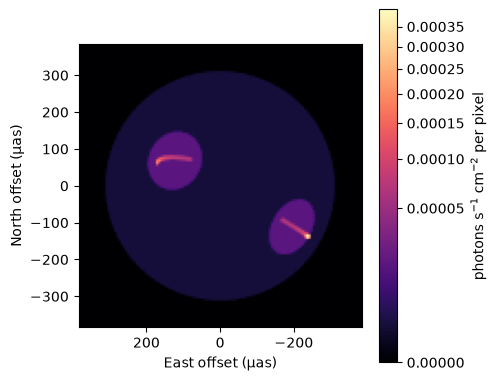

In [2]:
spec = {"kind": "blackbody", "kt": 1.0, "norm": 1.0}
rot = {"omega": 2 * np.pi / (0.5 * 86400), "axis": (0.0, 0.0, 1.0)}   # 0.5 d period
spots = [{"lat": 45, "lon": -60, "radius": 15, "intensity": 1.0},    # (the observer is at
         {"lat": -5, "lon": -125, "radius": 15, "intensity": 1.0}]   #  lat 30, lon -90)
star = Sphere(name="star", radius=1.0, rotation=rot, reflection=None,
              emission={"spectrum": spec, "intensity": 0.1, "spots": spots})
loops = [Loop(name=f"loop{k}", r_star=1.0, foot1=(s["lat"] - 8, s["lon"] - 8),
              foot2=(s["lat"] + 8, s["lon"] + 8), height=0.15, thickness=0.02, n0=1.0,
              rotation=rot, emission={"spectrum": spec, "j0": 2e-9}, n_fine=1024)
         for k, s in enumerate(spots)]
system = System3D(name="ab", length_unit="Rsun", inclination=60.0, node_pa=20.0,
                  bodies=[star], volumes=loops, supersample=3, chunk=1024)
grid = xm.RegularGrid(nx=128, ny=128, scale=6.0)                         # 6 uas pixels
scene = Scene(ra=82.1866, dec=-65.4498, distance_pc=15.0, grid=grid)     # AB Dor's position
scene.add(system)
model = scene.render()

# intensities above are relative (photons/s/cm^2/sr; loops ~ spots); scale the total to
# 0.03 photons/s/cm^2, an illustrative bright active star
total = sum(L.mean_photon_flux() for L in model.layers)
for L in model.layers:
    L.maps["NORM"] *= 0.03 / total
    print(f"{L.name:12s} {L.mean_photon_flux():.2e} photons/s/cm^2")

true = grid.to_image(sum(L.maps["NORM"] for L in model.layers))
h = grid.nx / 2 * grid.scale
fig, ax = plt.subplots(figsize=(5, 4.2))
im = ax.imshow(true, origin="lower", extent=[h, -h, -h, h], cmap="magma", norm=PowerNorm(0.4))
fig.colorbar(im, ax=ax, label="photons s$^{-1}$ cm$^{-2}$ per pixel")
ax.set_xlabel("East offset (µas)"); ax.set_ylabel("North offset (µas)")
fig.tight_layout()

## Simulate an observation

`XrimodelSource` returns photons at their absolute RA/Dec around the model's position, which is also
the default pointing. A reference point source at the same position, observed the same way, gives the
instrument's point-spread function (dirty beam) for comparison.

In [3]:
exposure = 5000.0   # s
inst = xs.Interferometer.from_arf(arf, roller=xs.instrument.smooth_roll)
src = xs.XrimodelSource(model)
photons = xs.generate_photons(src, arf, exposure, seed=1)
events = xs.redistribute(photons, inst, rmf, seed=2)
print(f"{len(photons)} photons, {len(events)} events")

fov = 0.0012   # arcsec, 1200 uas
img, span, _, meta = xs.reconstruct(events, inst, fov_arcsec=fov, use_true_energy=True)

point = xm.Model(ra=model.ra, dec=model.dec)
point.add(xm.SeparableLayer("pt", xm.blackbody(xm.energy_grid(), 1.0, 1.0)))
point.layers[0].spectrum.values *= 0.03 / point.layers[0].mean_photon_flux()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    ev_pt = xs.redistribute(xs.generate_photons(xs.XrimodelSource(point), arf, exposure, seed=3),
                            inst, rmf, seed=4)
psf, _, _, _ = xs.reconstruct(ev_pt, inst, fov_arcsec=fov, use_true_energy=True)
fwhm = 2.3548 * xs.beam_sigma_uas(psf, span / psf.shape[0])
print(f"image span {span:.0f} uas, pixel {span / img.shape[0]:.1f} uas, beam FWHM ~{fwhm:.0f} uas")

167727 photons, 167727 events
image span 1200 uas, pixel 4.7 uas, beam FWHM ~187 uas


## Comparison

The true image on the reconstruction's pixel grid, the true image convolved with the dirty beam (what a perfect instrument with this uv coverage would show) and the reconstruction. `use_true_energy` reconstructs the image with the photons' true energies. All three panels use the same square-root-like stretch, so the quiet corona over the whole disc shows on the image. The beam (~200 µas) resolves the two active regions and the star's extent, but not the loops; with the detected (CCD-resolution) energies the higher fringe orders decohere, which `fringe_taper` or the sub-band options of `reconstruct` mitigate.

Text(0, 0.5, 'North offset (µas)')

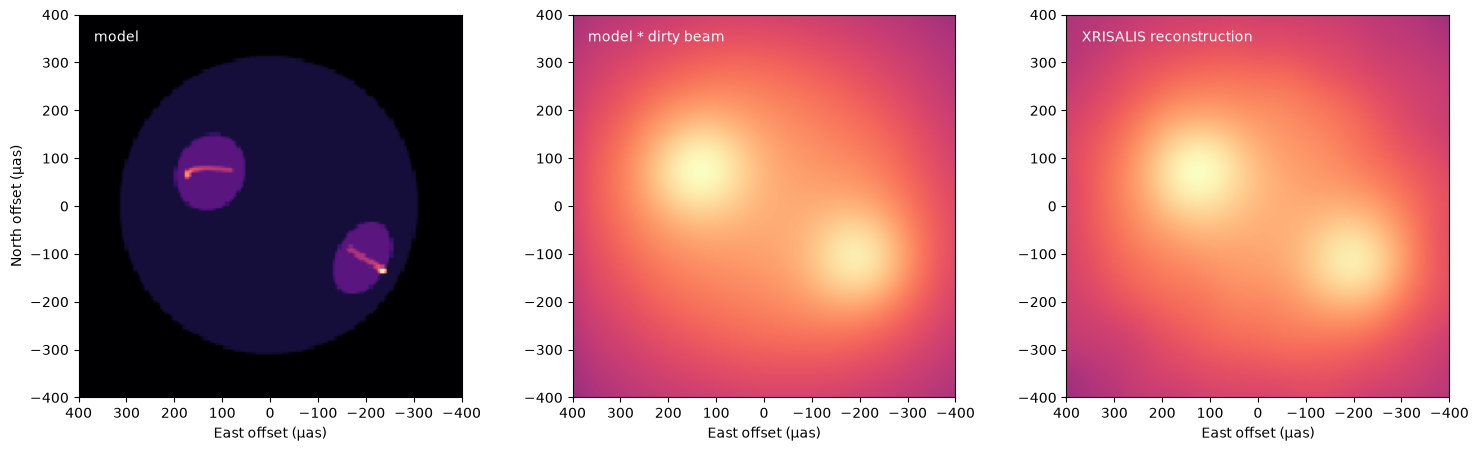

In [4]:
n = img.shape[0]
pix = span / n
c = (np.arange(n) - n / 2) * pix                     # reconstruction pixel centres (uas, East = +)
xc, yc = grid.centres()
# resample the model onto the reconstruction grid (nearest model pixel)
ix = np.clip(np.round((grid.nx / 2 - 0.5) - c / grid.scale).astype(int), 0, grid.nx - 1)
iy = np.clip(np.round(c / grid.scale + grid.ny / 2 - 0.5).astype(int), 0, grid.ny - 1)
true_r = true[np.ix_(iy, ix)]
conv = fftconvolve(true_r, psf / psf.sum(), mode="same")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.4), constrained_layout=True)
hr = span / 2
for a, im_, lab in [(ax[0], true_r, "model"), (ax[1], conv, "model * dirty beam"),
                    (ax[2], img, "XRISALIS reconstruction")]:
    a.imshow(np.clip(im_ / im_.max(), 0, None), origin="lower", extent=[-hr, hr, -hr, hr],
             cmap="magma", norm=PowerNorm(0.4, vmin=0, vmax=1))
    a.invert_xaxis()
    a.set_xlim(400, -400); a.set_ylim(-400, 400)
    a.text(0.04, 0.93, lab, transform=a.transAxes, color="w")
    a.set_xlabel("East offset (µas)")
ax[0].set_ylabel("North offset (µas)")